# What shapes a house price in Ames?

### An exploratory look at 1,460 home sales

This notebook walks through the Kaggle Ames housing training data to understand which home features tend to move with sale price. It is an exploratory analysis, not a price-prediction model: the patterns below describe this sample and do not establish cause and effect.

The data covers sales recorded in Ames, Iowa, from 2006 to 2010. The dollar figures are historical sale prices, not current market estimates. The `train.csv` file is included beside this notebook so the analysis runs without a separate download.

**Questions:** How uneven are prices? Which features track price most closely? Does quality matter in an ordered way? Do neighborhoods differ? Which unusual sales deserve a closer look? And which blanks actually mean “this home does not have that feature”?

**How to run:** Keep `train.csv` in the same folder as this notebook. The charts use pandas, NumPy, Matplotlib, Seaborn, and SciPy; install them in your Python environment if needed.

## 1. Load the data and take a first look

I’ll check the shape, column types, a few sample rows, and where information is missing before making any changes.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)

raw = pd.read_csv("train.csv")
df = raw.copy()
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())
df.info()
missing = df.isna().sum().sort_values(ascending=False)
missing = missing[missing.gt(0)]
display(pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(1)}))

Shape: 1,460 rows × 81 columns


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


<class 'pandas.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   str    
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   str    
 6   Alley          91 non-null     str    
 7   LotShape       1460 non-null   str    
 8   LandContour    1460 non-null   str    
 9   Utilities      1460 non-null   str    
 10  LotConfig      1460 non-null   str    
 11  LandSlope      1460 non-null   str    
 12  Neighborhood   1460 non-null   str    
 13  Condition1     1460 non-null   str    
 14  Condition2     1460 non-null   str    
 15  BldgType       1460 non-null   str    
 16  HouseStyle     1460 non-null   str    
 17  OverallQual    1460 non-null   int64  
 18  OverallCond    1460

,missing,percent
PoolQC,1453,99.5
MiscFeature,1406,96.3
Alley,1369,93.8
Fence,1179,80.8
MasVnrType,872,59.7
FireplaceQu,690,47.3
LotFrontage,259,17.7
GarageYrBlt,81,5.5
GarageCond,81,5.5
GarageType,81,5.5


**What I notice:** This is the expected 1,460-sale, 81-column file. Nineteen columns contain at least one blank, but several are mostly blank because the corresponding feature is absent (for example, a pool or alley). Treating every blank as an unknown would misdescribe the homes.

## 2. Classify the variables

Most numeric-looking columns are measurements or counts. `OverallQual` is the important exception: it is coded as a number, but the values are ordered quality grades. The two text quality grades also have a natural order.

In [2]:
numeric_cols = df.select_dtypes(include="number").columns.tolist()
categorical_cols = df.select_dtypes(include="object").columns.tolist()
ordinal_orders = {
    "ExterQual": ["Po", "Fa", "TA", "Gd", "Ex"],
    "KitchenQual": ["Po", "Fa", "TA", "Gd", "Ex"],
}
for col, order in ordinal_orders.items():
    df[col] = pd.Categorical(df[col], categories=order, ordered=True)

variable_summary = pd.DataFrame([
    {"column": col, "type": "ordinal (numeric code)" if col == "OverallQual" else "numeric" if col in numeric_cols else "ordinal" if col in ordinal_orders else "categorical",
     "unique values": raw[col].nunique(dropna=True), "examples": ", ".join(map(str, raw[col].dropna().unique()[:5]))}
    for col in raw.columns
])
display(variable_summary.head(24))

/var/folders/pk/psqlf0yj40xd7fw2b8w7bfy40000gn/T/ipykernel_2776/3858050022.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include="object").columns.tolist()


,column,type,unique values,examples
0,Id,numeric,1460,"1, 2, 3, 4, 5"
1,MSSubClass,numeric,15,"60, 20, 70, 50, 190"
2,MSZoning,categorical,5,"RL, RM, C (all), FV, RH"
3,LotFrontage,numeric,110,"65.0, 80.0, 68.0, 60.0, 84.0"
4,LotArea,numeric,1073,"8450, 9600, 11250, 9550, 14260"
5,Street,categorical,2,"Pave, Grvl"
6,Alley,categorical,2,"Grvl, Pave"
7,LotShape,categorical,4,"Reg, IR1, IR2, IR3"
8,LandContour,categorical,4,"Lvl, Bnk, Low, HLS"
9,Utilities,categorical,2,"AllPub, NoSeWa"


**What I notice:** Keeping the quality grades ordered makes comparisons easier to read. Other text columns, such as `Neighborhood` and `HouseStyle`, are labels rather than quantities; assigning them numeric codes would imply distances that are not really there.

## 3. Describe the centre and spread

The mean can be pulled upward by a small number of expensive homes, so I’m comparing it with the median as well as the range, quartiles, and skew.

In [3]:
display(df[numeric_cols].describe().T)
rows = []
for col in ["SalePrice", "GrLivArea", "LotArea"]:
    s = df[col]
    rows.append({"feature": col, "mean": s.mean(), "median": s.median(), "mode": s.mode().iloc[0],
                 "std": s.std(), "variance": s.var(), "min": s.min(), "max": s.max(),
                 "IQR": s.quantile(.75)-s.quantile(.25), "skew": s.skew(), "kurtosis": s.kurt()})
display(pd.DataFrame(rows).set_index("feature").round(2))
print("Most common neighborhood:", df["Neighborhood"].mode().iloc[0])
print("Most common house style:", df["HouseStyle"].mode().iloc[0])

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


,mean,median,mode,std,variance,min,max,IQR,skew,kurtosis
feature,,,,,,,,,,
SalePrice,180921.20,163000.0,140000,79442.50,6.311111e+09,34900,755000,84025.00,1.88,6.54
GrLivArea,1515.46,1464.0,864,525.48,2.761296e+05,334,5642,647.25,1.37,4.90
LotArea,10516.83,9478.5,7200,9981.26,9.962565e+07,1300,215245,4048.00,12.21,203.24


Most common neighborhood: NAmes
Most common house style: 1Story


**What I notice:** The typical sale was **$163,000** (the median), while the average was about **$180,921**. That $17,921 gap is a sign that a relatively small number of high-priced homes pull the average upward. Lot area is even more skewed: a few very large lots stretch its upper tail.

## 4. Look at the distributions

I’ll compare the raw sale-price distribution with its log version, then look at price across quality and neighborhood groups. The log view is only a way to see the shape more clearly; it does not change the original dollar values.

/var/folders/pk/psqlf0yj40xd7fw2b8w7bfy40000gn/T/ipykernel_2776/776342177.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df["SalePrice"], vert=True, patch_artist=True, boxprops={"facecolor":"#a9c9e8"})


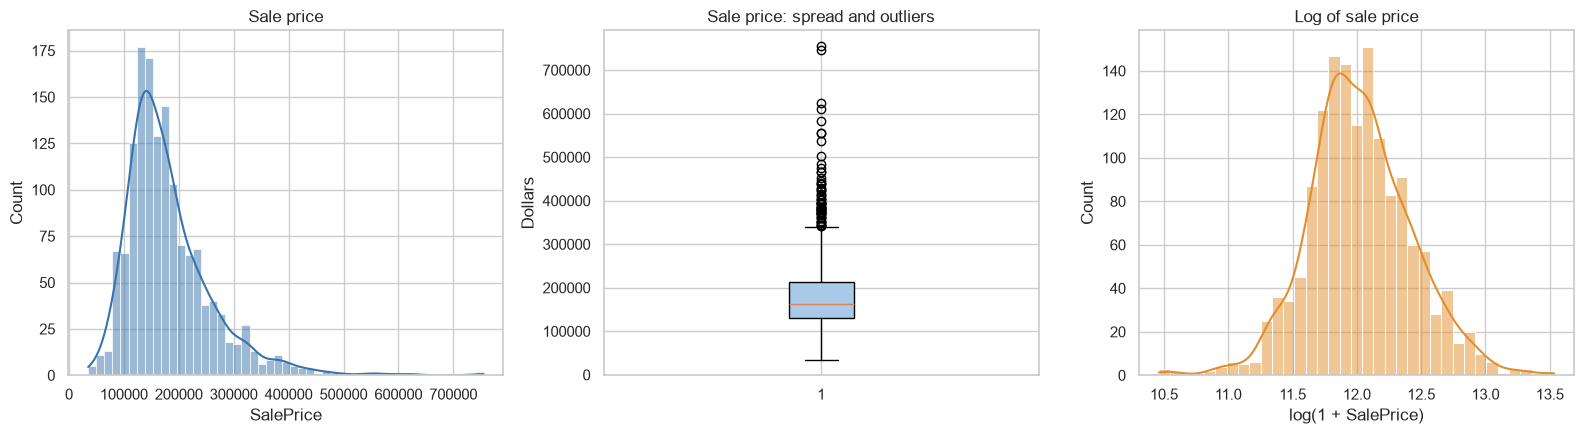

SalePrice skew: 1.88; log1p(SalePrice) skew: 0.12


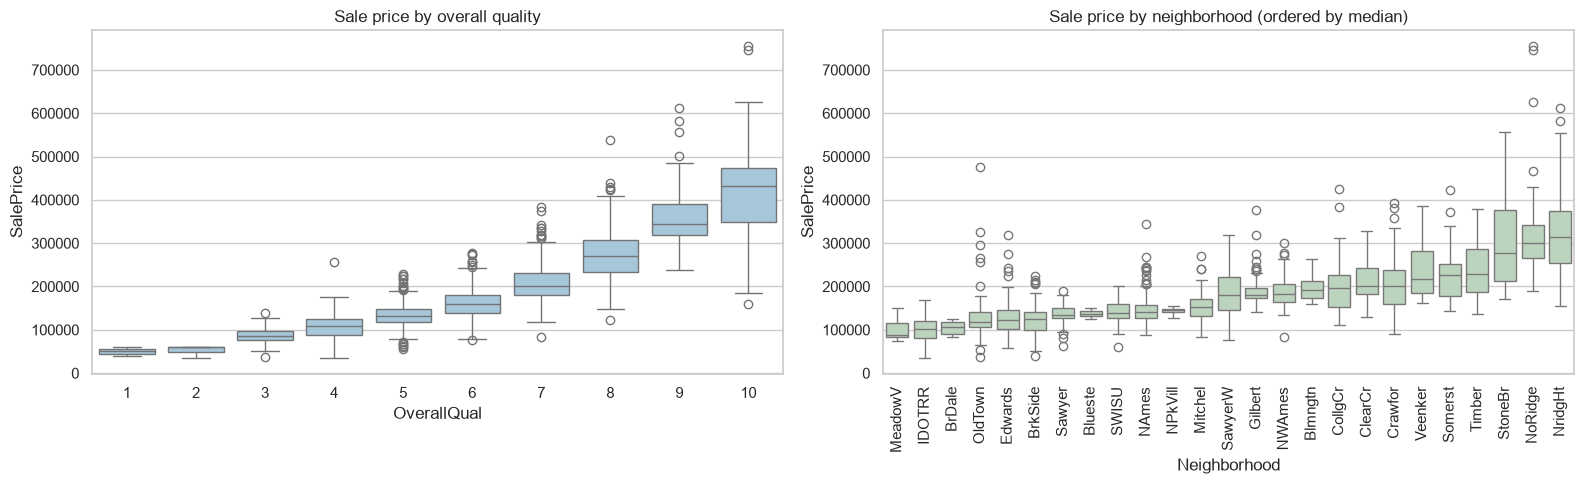

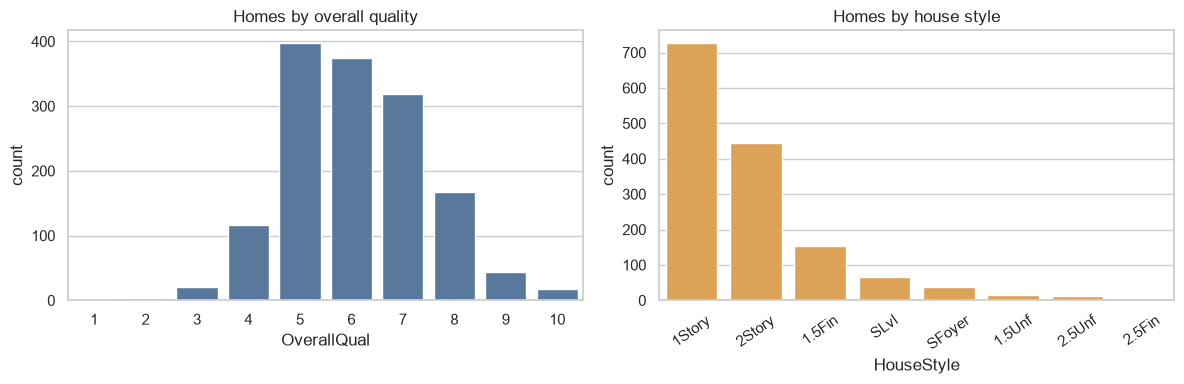

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.histplot(df["SalePrice"], kde=True, ax=axes[0], color="#3973ac")
axes[0].set_title("Sale price")
axes[1].boxplot(df["SalePrice"], vert=True, patch_artist=True, boxprops={"facecolor":"#a9c9e8"})
axes[1].set_title("Sale price: spread and outliers")
axes[1].set_ylabel("Dollars")
sns.histplot(np.log1p(df["SalePrice"]), kde=True, ax=axes[2], color="#e28e2c")
axes[2].set_title("Log of sale price")
axes[2].set_xlabel("log(1 + SalePrice)")
plt.tight_layout()
plt.show()
print(f"SalePrice skew: {df.SalePrice.skew():.2f}; log1p(SalePrice) skew: {np.log1p(df.SalePrice).skew():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.boxplot(data=df, x="OverallQual", y="SalePrice", ax=axes[0], color="#9ecae1")
axes[0].set_title("Sale price by overall quality")
med_order = df.groupby("Neighborhood", observed=True).SalePrice.median().sort_values().index
sns.boxplot(data=df, x="Neighborhood", y="SalePrice", order=med_order, ax=axes[1], color="#b8d8ba")
axes[1].set_title("Sale price by neighborhood (ordered by median)")
axes[1].tick_params(axis="x", rotation=90)
plt.tight_layout()
plt.show()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="OverallQual", ax=axes[0], color="#4c78a8")
sns.countplot(data=df, x="HouseStyle", order=df.HouseStyle.value_counts().index, ax=axes[1], color="#f2a541")
axes[1].tick_params(axis="x", rotation=35)
axes[0].set_title("Homes by overall quality")
axes[1].set_title("Homes by house style")
plt.tight_layout()
plt.show()

**What I notice:** Sale prices are right-skewed (skew **1.88**); after a log transform the skew drops to **0.12**, so the distribution looks much more balanced. Median prices rise at each quality level from 3 upward, from **$86,250** at grade 3 to **$432,390** at grade 10. The upper quality groups are small, and their prices vary more widely. Neighborhood medians also differ substantially; the ten highest are summarized below.

In [5]:
neighborhood_summary = df.groupby("Neighborhood", observed=True).SalePrice.agg(sales="size", median="median", mean="mean").sort_values("median", ascending=False).head(10)
display(neighborhood_summary.assign(median=neighborhood_summary["median"].map(lambda x: f"${x:,.0f}"), mean=neighborhood_summary["mean"].map(lambda x: f"${x:,.0f}")))

,sales,median,mean
Neighborhood,,,
NridgHt,77,"$315,000","$316,271"
NoRidge,41,"$301,500","$335,295"
StoneBr,25,"$278,000","$310,499"
Timber,38,"$228,475","$242,247"
Somerst,86,"$225,500","$225,380"
Veenker,11,"$218,000","$238,773"
Crawfor,51,"$200,624","$210,625"
ClearCr,28,"$200,250","$212,565"
CollgCr,150,"$197,200","$197,966"


## 5. Correlation: what moves with price?

Pearson correlation puts relationships on a common scale from -1 to 1, so it is easier to compare than covariance, whose size depends on the units (dollars, square feet, and so on). Correlation describes a linear association; it does not tell us that one feature causes another.

In [6]:
num = df.select_dtypes(include="number")
corr = num.corr(numeric_only=True)
top_price = corr["SalePrice"].drop("SalePrice").abs().sort_values(ascending=False).head(10)
price_corr = corr.loc[top_price.index, "SalePrice"].sort_values(ascending=False)
display(price_corr.rename("correlation with SalePrice").to_frame())
cov = num.cov()["SalePrice"].reindex(price_corr.index)
display(pd.DataFrame({"correlation": price_corr, "covariance with SalePrice": cov.loc[price_corr.index]}).head(3))
print(f"GarageArea and GarageCars correlation: {corr.loc['GarageArea','GarageCars']:.2f}")

,correlation with SalePrice
OverallQual,0.790982
GrLivArea,0.708624
GarageCars,0.640409
GarageArea,0.623431
TotalBsmtSF,0.613581
1stFlrSF,0.605852
FullBath,0.560664
TotRmsAbvGrd,0.533723
YearBuilt,0.522897
YearRemodAdd,0.507101


,correlation,covariance with SalePrice
OverallQual,0.790982,8.690413e+04
GrLivArea,0.708624,2.958187e+07
GarageCars,0.640409,3.802018e+04


GarageArea and GarageCars correlation: 0.88


**What I notice:** Overall quality (**0.79**) and above-ground living area (**0.71**) have the strongest linear relationships with sale price. Garage capacity and size, basement area, and first-floor area also rank highly. `GarageArea` and `GarageCars` correlate at **0.88** because larger garages generally hold more cars. That overlap matters: two highly related measurements may tell a similar story, and their correlations should not be mistaken for separate causal effects.

## 6. See the relationships directly

The scatter plots help reveal whether a relationship is roughly straight and whether a handful of homes behave differently from the rest. I’ve highlighted very large homes that sold for under $300,000 for a closer look.

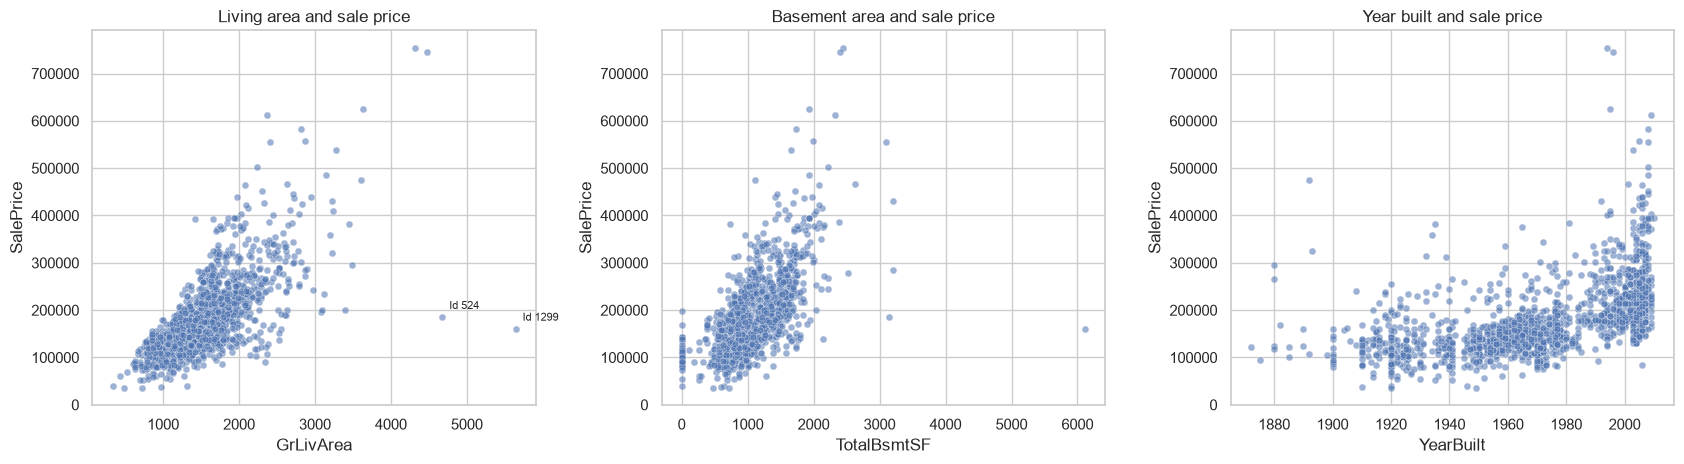

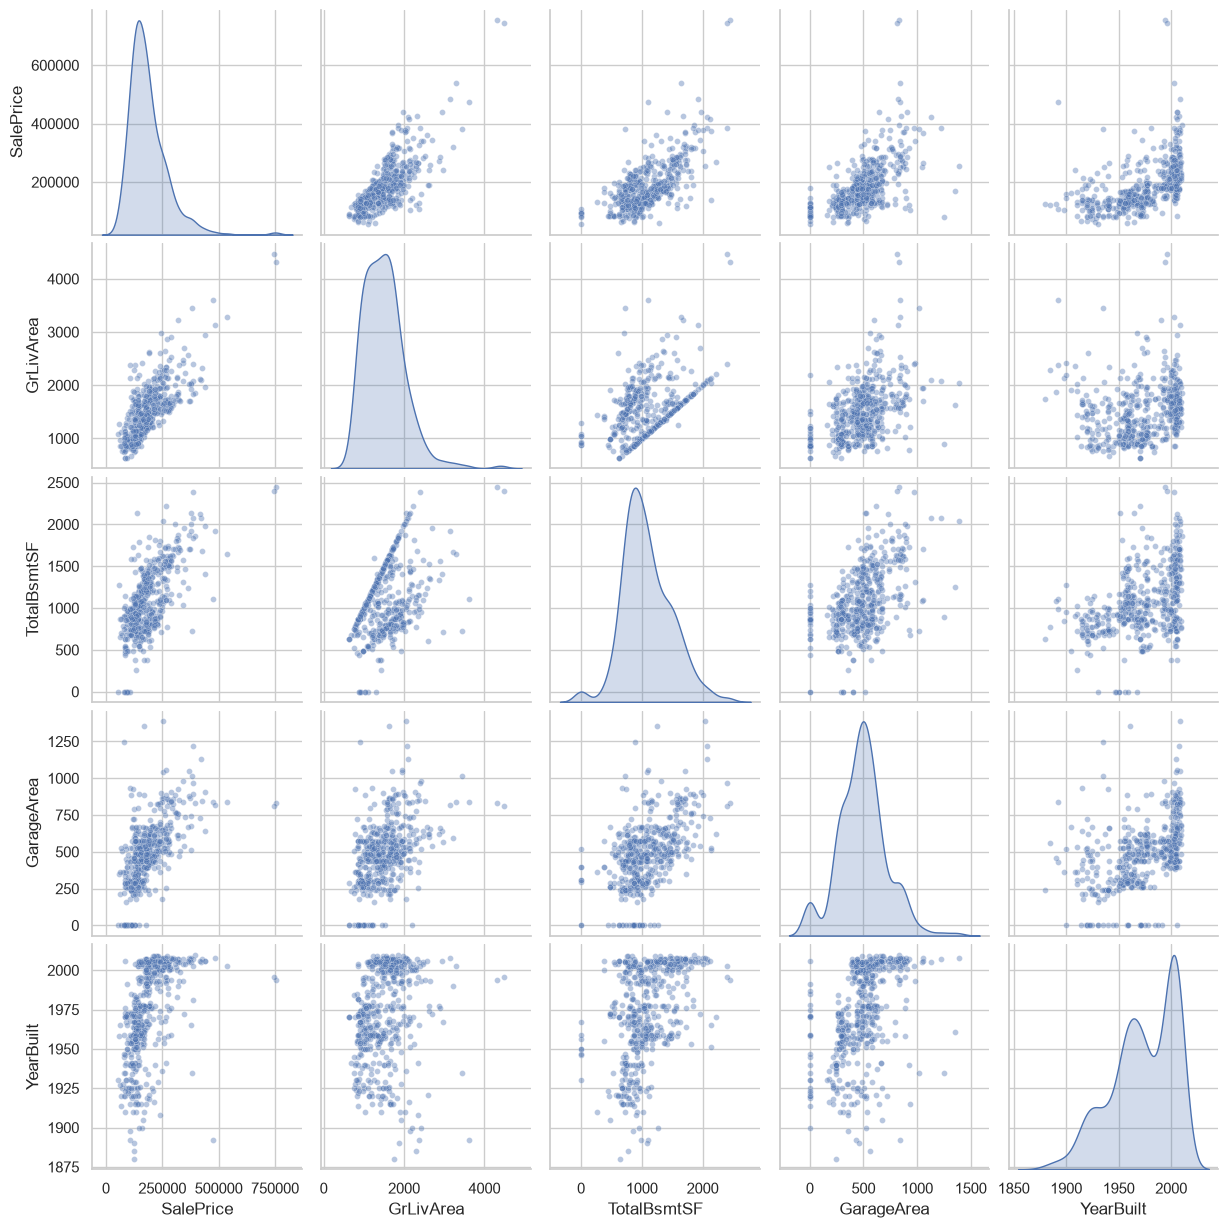

,Id,GrLivArea,SalePrice,OverallQual,Neighborhood
523,524,4676,184750,10,Edwards
1298,1299,5642,160000,10,Edwards


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, x, title in zip(axes, ["GrLivArea", "TotalBsmtSF", "YearBuilt"], ["Living area", "Basement area", "Year built"]):
    sns.scatterplot(data=df, x=x, y="SalePrice", alpha=.55, s=25, ax=ax)
    ax.set_title(f"{title} and sale price")
large_cheap = df[(df.GrLivArea > 4000) & (df.SalePrice < 300000)]
for _, row in large_cheap.iterrows():
    axes[0].annotate(f"Id {int(row.Id)}", (row.GrLivArea, row.SalePrice), xytext=(5, 6), textcoords="offset points", fontsize=8)
plt.tight_layout()
plt.show()
selected = ["SalePrice", "GrLivArea", "TotalBsmtSF", "GarageArea", "YearBuilt"]
sns.pairplot(df[selected].sample(min(500, len(df)), random_state=7), diag_kind="kde", plot_kws={"alpha":.4, "s":18})
plt.show()
display(large_cheap[["Id","GrLivArea","SalePrice","OverallQual","Neighborhood"]])

**What I notice:** Price generally rises with living area, basement area, and newer construction, though none of these relationships is perfectly tidy. Two especially large homes stand out: IDs **524** and **1299** have 4,676 and 5,642 square feet but sold for $184,750 and $160,000. Their recorded overall quality is 10, so they are unusual sales rather than obvious typing errors. I keep them in the main analysis and call them out rather than silently deleting them.

## 7. A compact correlation heatmap

Showing one half of the matrix avoids printing the same relationship twice.

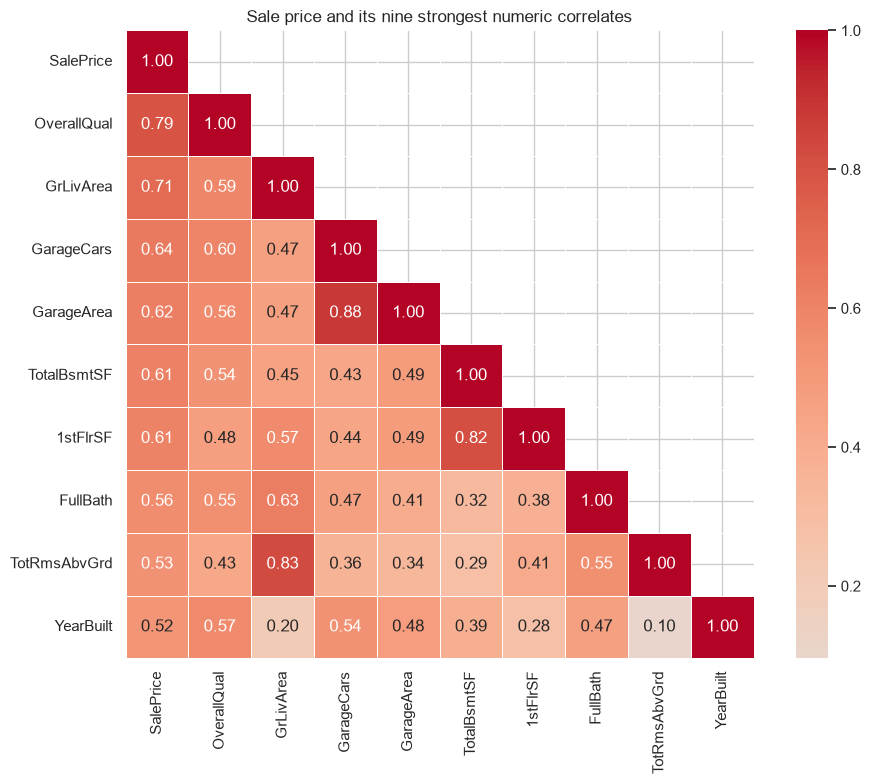

In [8]:
top_features = ["SalePrice"] + top_price.index[:9].tolist()
heat = df[top_features].corr(numeric_only=True)
mask = np.triu(np.ones_like(heat, dtype=bool), k=1)
plt.figure(figsize=(10, 8))
sns.heatmap(heat, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, linewidths=.5)
plt.title("Sale price and its nine strongest numeric correlates")
plt.tight_layout()
plt.show()

**What I notice:** The heatmap reinforces the main pattern: size, quality, and garage capacity tend to rise with price. It also makes the overlap between features visible. For example, living area is related to both total rooms and first-floor area, so the table is a map of associations, not a list of independent price levers.

## 8. Flag outliers, then use judgement

IQR fences and a three-standard-deviation z-score are two ways to flag unusual values. They answer slightly different questions, and neither method knows whether a sale is a mistake.

,IQR flags,z-score flags,flagged by both
feature,,,
GrLivArea,31,16,16
SalePrice,61,22,22


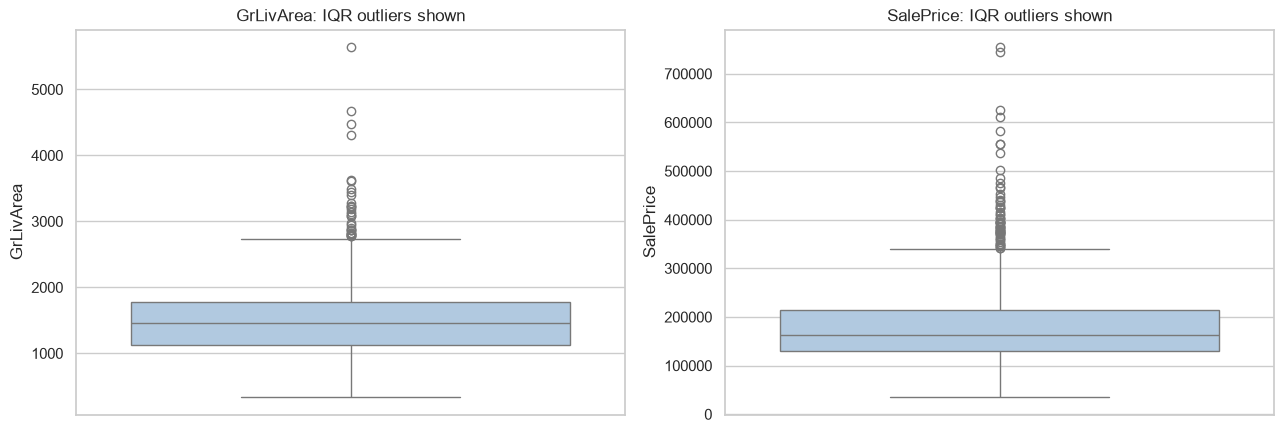

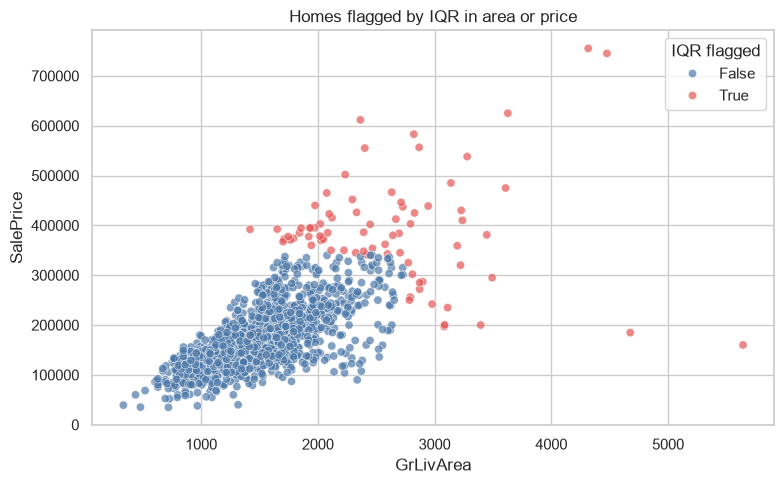

In [9]:
def iqr_flags(series):
    q1, q3 = series.quantile([.25, .75])
    fence = 1.5 * (q3 - q1)
    return (series < q1 - fence) | (series > q3 + fence)

def zscore_flags(series, threshold=3):
    return stats.zscore(series, nan_policy="omit", ddof=1).__abs__() > threshold

outlier_rows = []
flag_map = {}
for col in ["GrLivArea", "SalePrice"]:
    iqr = iqr_flags(df[col])
    z = zscore_flags(df[col])
    flag_map[col] = (iqr, z)
    outlier_rows.append({"feature":col, "IQR flags":int(iqr.sum()), "z-score flags":int(z.sum()), "flagged by both":int((iqr & z).sum())})
display(pd.DataFrame(outlier_rows).set_index("feature"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, col in zip(axes, ["GrLivArea", "SalePrice"]):
    sns.boxplot(y=df[col], ax=ax, color="#a9c9e8")
    ax.set_title(f"{col}: IQR outliers shown")
plt.tight_layout(); plt.show()
area_iqr, area_z = flag_map["GrLivArea"]
price_iqr, price_z = flag_map["SalePrice"]
fig, ax = plt.subplots(figsize=(8, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", hue=area_iqr | price_iqr, palette={False:"#4c78a8", True:"#e45756"}, alpha=.7, ax=ax)
ax.set_title("Homes flagged by IQR in area or price")
ax.legend(title="IQR flagged")
plt.tight_layout(); plt.show()

**What I notice:** IQR flags **31** living-area values and **61** sale prices; z-scores flag **16** and **22**, respectively, and every z-score flag overlaps an IQR flag. On a skewed distribution, the mean and standard deviation are pulled toward the long upper tail, making the three-standard-deviation cutoff more forgiving for extreme high values. These counts are prompts to inspect records, not a reason to delete them. The two very large, comparatively inexpensive homes remain in the dataset.

## 9. Check data quality and handle missing values

I’m checking duplicates, inconsistent text labels, and impossible dates or areas. Then I’ll distinguish “feature absent” blanks from measurements that are genuinely unavailable. The original `raw` frame stays intact.

In [10]:
print("Exact duplicate rows:", raw.duplicated().sum())
print("Year built after year sold:", (raw.YearBuilt > raw.YrSold).sum())
area_cols = [c for c in raw.columns if c.endswith("Area") or c in ["LotArea", "TotalBsmtSF", "GrLivArea"]]
print("Negative values in area fields:", int((raw[area_cols] < 0).sum().sum()))
# Look for accidental whitespace or inconsistent casing in text columns
label_issues = {}
for col in categorical_cols:
    vals = raw[col].dropna().astype(str)
    if vals.str.strip().ne(vals).any() or vals.str.lower().nunique() < vals.nunique():
        label_issues[col] = vals[vals.str.strip().ne(vals) | vals.str.lower().duplicated(keep=False)].unique().tolist()[:10]
print("Potential casing/spacing issues:", label_issues or "none found")

clean = raw.copy()
absence_means_none = ["PoolQC", "MiscFeature", "Alley", "Fence", "MasVnrType", "FireplaceQu",
                      "GarageType", "GarageFinish", "GarageQual", "GarageCond",
                      "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2"]
clean[absence_means_none] = clean[absence_means_none].fillna("None")
clean["MasVnrArea"] = clean["MasVnrArea"].fillna(0)  # no masonry veneer
clean["LotFrontage"] = clean["LotFrontage"].fillna(clean.groupby("Neighborhood")["LotFrontage"].transform("median"))
clean["LotFrontage"] = clean["LotFrontage"].fillna(clean["LotFrontage"].median())
clean["Electrical"] = clean["Electrical"].fillna(clean["Electrical"].mode()[0])
remaining = clean.isna().sum()
display(remaining[remaining.gt(0)].rename("remaining missing values").to_frame())

Exact duplicate rows: 0
Year built after year sold: 0
Negative values in area fields: 0
Potential casing/spacing issues: none found


,remaining missing values
GarageYrBlt,81


**What I notice:** There are no duplicate rows, impossible build/sale year pairs, negative area measurements, or obvious casing and spacing problems. The structural blanks now say `None`; missing veneer area is set to zero; frontage is filled using the neighborhood median (then the overall median if needed); and the single missing electrical label uses the most common category. I leave the **81 missing garage build years** blank: those homes have no garage, so inventing a construction year would be misleading. In other words, the cleaned analysis frame keeps one intentional group of missing values.

## 10. Put the story on one dashboard

This final figure collects four views: average price by year built, the ten highest-mean neighborhoods, the price distribution with its mean and median, and living area versus price colored by quality.

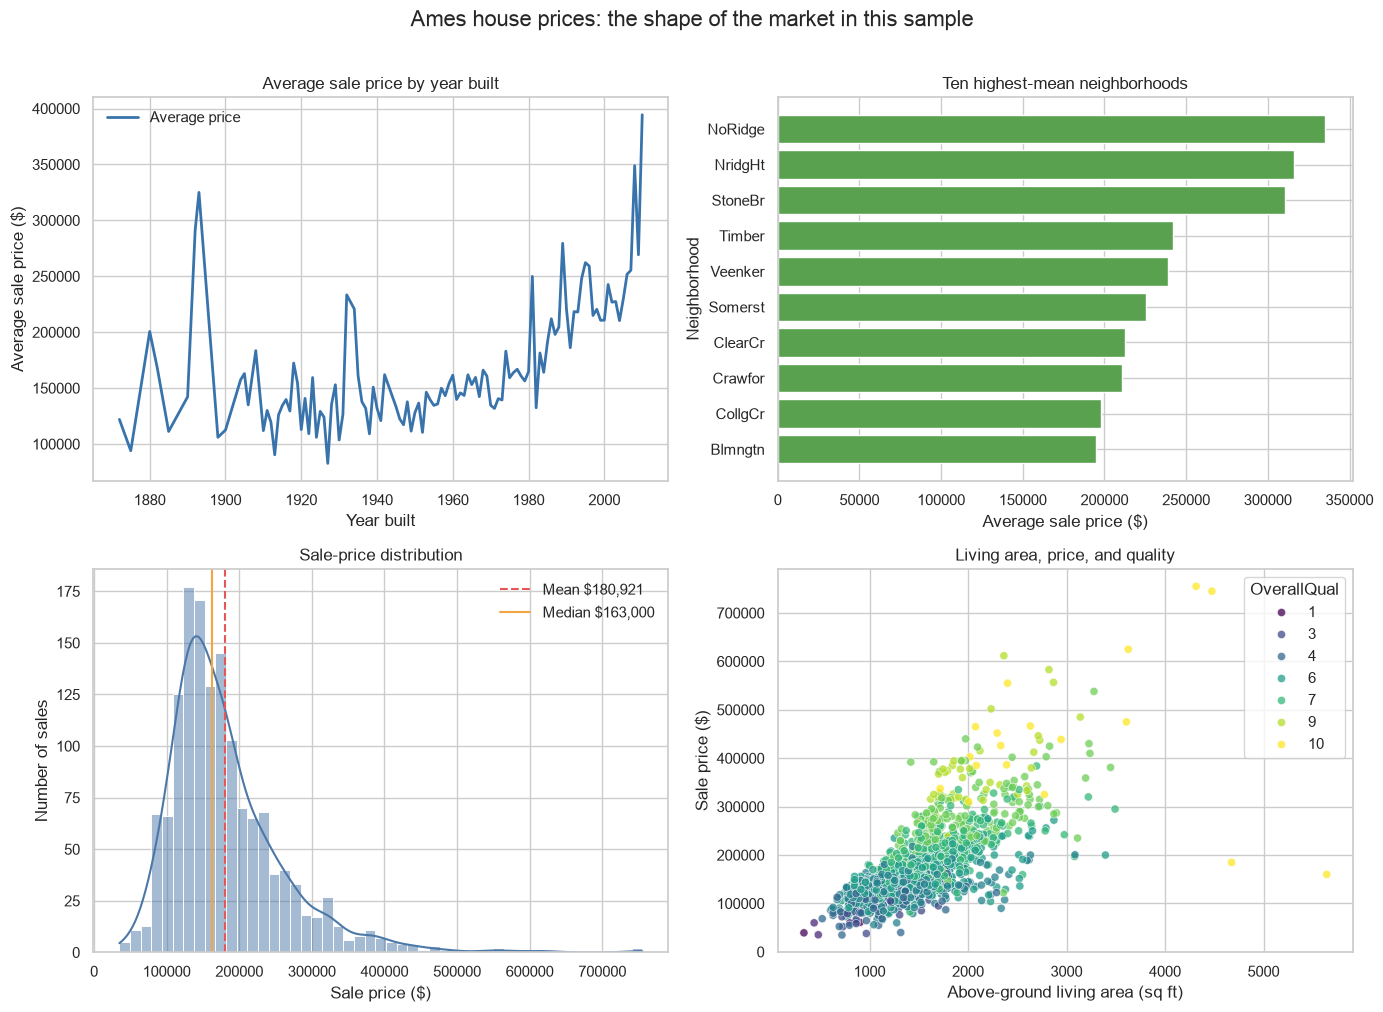

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
by_year = df.groupby("YearBuilt").SalePrice.mean().sort_index()
axes[0,0].plot(by_year.index, by_year.values, color="#3973ac", linewidth=2, label="Average price")
axes[0,0].set(title="Average sale price by year built", xlabel="Year built", ylabel="Average sale price ($)")
axes[0,0].legend(frameon=False)
by_neigh = df.groupby("Neighborhood").SalePrice.mean().nlargest(10).sort_values()
axes[0,1].barh(by_neigh.index, by_neigh.values, color="#59a14f")
axes[0,1].set(title="Ten highest-mean neighborhoods", xlabel="Average sale price ($)", ylabel="Neighborhood")
sns.histplot(df.SalePrice, kde=True, ax=axes[1,0], color="#4c78a8")
axes[1,0].axvline(df.SalePrice.mean(), color="#e45756", linestyle="--", label=f"Mean ${df.SalePrice.mean():,.0f}")
axes[1,0].axvline(df.SalePrice.median(), color="#f2a541", linestyle="-", label=f"Median ${df.SalePrice.median():,.0f}")
axes[1,0].set(title="Sale-price distribution", xlabel="Sale price ($)", ylabel="Number of sales")
axes[1,0].legend(frameon=False)
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", hue="OverallQual", palette="viridis", alpha=.75, s=35, ax=axes[1,1])
axes[1,1].set(title="Living area, price, and quality", xlabel="Above-ground living area (sq ft)", ylabel="Sale price ($)")
fig.suptitle("Ames house prices: the shape of the market in this sample", fontsize=16, y=1.01)
plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=180, bbox_inches="tight")
plt.show()

## What the data says

- **Prices are uneven.** The median sale was $163,000, below the $180,921 average. A log transform makes the price distribution much more balanced, but most of the story can still be told in the original dollars.
- **Quality and usable space stand out.** Overall quality has the strongest numerical correlation with sale price (0.79), followed by above-ground living area (0.71). Median price rises steadily across the common quality grades and reaches $432,390 for grade 10, though only 18 homes are in that top group.
- **Where a home sits matters in this sample.** The top neighborhood median is $315,000 in NridgHt, compared with $301,500 in NoRidge and $278,000 in StoneBr. These are sample summaries, not guarantees for individual homes.
- **Some unusual records are still plausible.** A few homes are flagged as outliers, including two very large houses sold well below what their size might suggest. Their quality scores are high and the records are not obviously invalid, so I keep them and explain their influence.
- **Blank does not always mean unknown.** Many missing values mean the home has no pool, alley, fence, fireplace, garage, or basement feature. Those are represented as `None`; the no-garage build years remain blank rather than being fabricated.

### Limits to keep in mind

These are historical Ames sales from 2006–2010. Correlation is not causation, group sizes vary (especially at the quality extremes), and the analysis does not adjust for inflation or account for every property detail. Use it to describe patterns in this dataset, not to estimate what a home is worth today.

### Data and references

- Dataset: Kaggle, [House Prices: Advanced Regression Techniques](https://www.kaggle.com/competitions/house-prices-advanced-regression-techniques/data). The included CSV is the training file mirrored at [GitHub](https://github.com/djeada/Kaggle-House-Prices/blob/main/data/train.csv).
- Method: descriptive summaries, distributions, correlations, visual inspection, IQR fences, and z-scores. No machine-learning model is used.